# Retail Demand Forecasting & Inventory Planning
### End-to-end Data Science project using the supplied M5 dataset

**Objective:** understand historical retail demand, build and compare forecasting models, evaluate them with leakage-safe rolling-origin backtesting, forecast future demand, and translate forecast uncertainty into illustrative inventory scenarios.

**Data rule:** the notebook only uses values present in the supplied CSVs. Lead time, service level, review period and on-hand inventory are scenario assumptions because the dataset does not contain them. No missing sales or prices are silently invented.

> **Execution note:** The saved metric tables in this notebook are from the original baseline run. The added time-aware XGBoost tuning section computes candidate scores and refreshes model comparison, error analysis, final forecasts, inventory plans, and CSV exports when you run the notebook from top to bottom. Tuned metric values are intentionally not pre-filled or invented.

## 1. Environment and project configuration
Import libraries and define the modelling scope, forecast horizon, backtest windows and inventory assumptions. The default includes all observed stores and the top two products per category and store (up to 60 series). Increase TOP_N_PER_CATEGORY or set it to None to expand toward all eligible products; full-product modelling may require substantial Colab RAM and runtime.

In [1]:
import os, re, sys, warnings, importlib.util
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Colab: upload the five CSV files to /content. Local Jupyter: put them beside this notebook.
DATA_DIR = "/content" if os.path.isdir("/content") else "."
FILES = {
    "validation": "sales_train_validation.csv",
    "evaluation": "sales_train_evaluation.csv",
    "calendar": "calendar.csv",
    "prices": "sell_prices.csv",
    "submission": "sample_submission.csv",
}

# Modelling scope: "ALL" uses all observed stores; otherwise specify a store such as "CA_1".
STORE_SCOPE = "ALL"
# Number of products per category and store, selected using ONLY the earliest backtest training window.
# Set to None to use every eligible product (can be slow on the full dataset).
TOP_N_PER_CATEGORY = 2

HORIZON = 28
N_BACKTEST_ORIGINS = 4
RANDOM_STATE = 42
MIN_TRAIN_DAYS = 365

# Inventory scenario assumptions: these are NOT supplied by the dataset.
LEAD_TIME_DAYS = 7
REVIEW_PERIOD_DAYS = 7
SERVICE_LEVEL = 0.95
ON_HAND_UNITS = 0

OUTPUT_DIR = Path("retail_forecasting_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Configuration ready.")

Configuration ready.


## 2. Load all supplied CSV files
Read the validation, evaluation, calendar, selling-price and sample-submission files. The validation snapshot is used for backtesting; the evaluation snapshot is used only for the final forecast.

In [2]:
paths = {k: Path(DATA_DIR) / v for k, v in FILES.items()}
missing_files = [str(p) for p in paths.values() if not p.exists()]
if missing_files:
    raise FileNotFoundError("Upload/place these files before running: " + ", ".join(missing_files))

sales_val = pd.read_csv(paths["validation"])
sales_eval = pd.read_csv(paths["evaluation"])
calendar = pd.read_csv(paths["calendar"])
prices = pd.read_csv(paths["prices"])
sample_submission = pd.read_csv(paths["submission"])

for name, df in [("validation", sales_val), ("evaluation", sales_eval),
                 ("calendar", calendar), ("prices", prices), ("submission", sample_submission)]:
    print(f"{name:12s}: {df.shape}")

validation  : (1869, 1919)
evaluation  : (1843, 1947)
calendar    : (1969, 14)
prices      : (236913, 4)
submission  : (60980, 29)


In [3]:
# Reload the original CSV into a separate variable
sales_val_check = pd.read_csv(paths["validation"])

print("Original validation CSV categories:")
print(sales_val_check["cat_id"].value_counts())

print("\nEvaluation CSV categories:")
print(sales_eval["cat_id"].value_counts())

print("\nStores in validation CSV:")
print(sales_val_check["store_id"].value_counts())

Original validation CSV categories:
cat_id
HOUSEHOLD    1047
HOBBIES       565
FOODS         257
Name: count, dtype: int64

Evaluation CSV categories:
cat_id
HOUSEHOLD    1047
HOBBIES       565
FOODS         231
Name: count, dtype: int64

Stores in validation CSV:
store_id
CA_1    1869
Name: count, dtype: int64


In [4]:
# Restore the complete validation dataset
sales_val = sales_val_check

print("Restored validation dataset:", sales_val.shape)
print("\nCategory distribution:")
print(sales_val["cat_id"].value_counts())

Restored validation dataset: (1869, 1919)

Category distribution:
cat_id
HOUSEHOLD    1047
HOBBIES       565
FOODS         257
Name: count, dtype: int64


In [5]:
sales_eval_check = pd.read_csv(paths["evaluation"])

print("Original evaluation dataset:", sales_eval_check.shape)
print("\nEvaluation categories:")
print(sales_eval_check["cat_id"].value_counts())

Original evaluation dataset: (1843, 1947)

Evaluation categories:
cat_id
HOUSEHOLD    1047
HOBBIES       565
FOODS         231
Name: count, dtype: int64


## 3. Dataset integrity and actual scope
Identify daily sales columns from their names, inspect keys, missing values, duplicate rows, negative sales and the categories/stores actually present. Missing observations remain missing; they are never converted to zero.

In [6]:
def day_columns(df):
    return sorted([c for c in df.columns if re.fullmatch(r"d_\d+", str(c))],
                  key=lambda x: int(x.split("_")[1]))

val_days, eval_days = day_columns(sales_val), day_columns(sales_eval)
metadata_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]

def audit_sales(df, days, label):
    numeric = df[days].apply(pd.to_numeric, errors="coerce")
    return {
        "snapshot": label, "rows": len(df), "daily_columns": len(days),
        "first_day": days[0], "last_day": days[-1],
        "unique_series": df["id"].nunique(),
        "duplicate_ids": int(df["id"].duplicated().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_sales_cells": int(numeric.isna().sum().sum()),
        "negative_sales_cells": int((numeric < 0).sum().sum()),
        "stores": int(df["store_id"].nunique()),
        "products": int(df["item_id"].nunique()),
        "categories": int(df["cat_id"].nunique())
    }

audit = pd.DataFrame([audit_sales(sales_val, val_days, "validation"),
                      audit_sales(sales_eval, eval_days, "evaluation")])
display(audit)

print("Validation stores:", sorted(sales_val.store_id.unique()))
print("Validation categories:", sorted(sales_val.cat_id.unique()))
print("Departments:", sorted(sales_val.dept_id.unique()))
print("Calendar date range:", pd.to_datetime(calendar.date).min(), "to", pd.to_datetime(calendar.date).max())
print("Calendar duplicate day IDs:", calendar["d"].duplicated().sum())
print("Price duplicate store-item-week keys:",
      prices.duplicated(["store_id", "item_id", "wm_yr_wk"]).sum())
print("Sample submission shape:", sample_submission.shape)

,snapshot,rows,daily_columns,first_day,last_day,unique_series,duplicate_ids,duplicate_rows,missing_sales_cells,negative_sales_cells,stores,products,categories
0,validation,1869,1913,d_1,d_1913,1869,0,0,680,0,1,1869,3
1,evaluation,1843,1941,d_1,d_1941,1843,0,0,809,0,1,1843,3


Validation stores: ['CA_1']
Validation categories: ['FOODS', 'HOBBIES', 'HOUSEHOLD']
Departments: ['FOODS_1', 'FOODS_2', 'HOBBIES_1', 'HOBBIES_2', 'HOUSEHOLD_1', 'HOUSEHOLD_2']
Calendar date range: 2011-01-29 00:00:00 to 2016-06-19 00:00:00
Calendar duplicate day IDs: 0
Price duplicate store-item-week keys: 0
Sample submission shape: (60980, 29)


## 4. Cross-file integrity checks
Check that validation and evaluation snapshots represent the same item-store series using stable keys rather than their different ID suffixes. Check calendar coverage and price-key uniqueness before joining.

In [7]:
key_cols = ["item_id", "store_id"]
val_keys = sales_val[key_cols + ["dept_id", "cat_id", "state_id"]].drop_duplicates(key_cols)
eval_keys = sales_eval[key_cols + ["dept_id", "cat_id", "state_id"]].drop_duplicates(key_cols)
key_match = val_keys.merge(eval_keys, on=key_cols, how="outer", suffixes=("_val", "_eval"), indicator=True)
print("Item-store pairs in both snapshots:", int((key_match._merge == "both").sum()))
print("Validation-only pairs:", int((key_match._merge == "left_only").sum()))
print("Evaluation-only pairs:", int((key_match._merge == "right_only").sum()))
both = key_match[key_match._merge == "both"]
meta_mismatch = ((both.dept_id_val != both.dept_id_eval) |
                 (both.cat_id_val != both.cat_id_eval) |
                 (both.state_id_val != both.state_id_eval)).sum()
print("Metadata mismatches among matched pairs:", int(meta_mismatch))

calendar = calendar.copy()
calendar["date"] = pd.to_datetime(calendar["date"])
calendar["d_num"] = calendar["d"].str.extract(r"(\d+)").astype(int)
calendar = calendar.sort_values("d_num").drop_duplicates("d_num")
calendar_lookup = calendar.set_index("d_num").to_dict(orient="index")
print("Calendar day IDs:", calendar.d_num.min(), "to", calendar.d_num.max())
print("Price rows:", len(prices), "| unique items:", prices.item_id.nunique(),
      "| unique stores:", prices.store_id.nunique())

Item-store pairs in both snapshots: 1843
Validation-only pairs: 26
Evaluation-only pairs: 0
Metadata mismatches among matched pairs: 0
Calendar day IDs: 1 to 1969
Price rows: 236913 | unique items: 1052 | unique stores: 1


## 5. Choose a leakage-safe modelling scope
The four backtest windows are the final consecutive 28-day blocks in the validation snapshot. Product selection uses only data available before the first backtest origin. This prevents holdout demand from influencing which products enter the experiment.

In [8]:
if len(val_days) < HORIZON * N_BACKTEST_ORIGINS + MIN_TRAIN_DAYS:
    raise ValueError("Not enough validation history for the requested rolling-origin setup.")

val_day_nums = np.array([int(x.split("_")[1]) for x in val_days])
first_test_start = int(val_day_nums[-HORIZON * N_BACKTEST_ORIGINS])
first_train_end = first_test_start - 1
print("Earliest backtest training ends at d_", first_train_end, sep="")
print("Backtest test window begins at d_", first_test_start, sep="")

if STORE_SCOPE == "ALL":
    eligible = sales_val.copy()
else:
    eligible = sales_val[sales_val.store_id == STORE_SCOPE].copy()
    if eligible.empty:
        raise ValueError(f"STORE_SCOPE={STORE_SCOPE} not found in validation data.")

selection_days = [d for d in val_days if int(d.split("_")[1]) <= first_train_end]
selection_sales = eligible[metadata_cols + selection_days].copy()
selection_sales["selection_units"] = selection_sales[selection_days].sum(axis=1, min_count=1)

if TOP_N_PER_CATEGORY is None:
    selected_ids = selection_sales["id"].tolist()
else:
    selected_ids = []
    for (store, cat), group in selection_sales.groupby(["store_id", "cat_id"]):
        selected_ids.extend(group.nlargest(TOP_N_PER_CATEGORY, "selection_units")["id"].tolist())

scope = eligible[eligible.id.isin(selected_ids)].copy()
scope_summary = selection_sales[selection_sales.id.isin(selected_ids)].groupby(
    ["store_id", "cat_id"]
).agg(selected_series=("id", "nunique"),
      selected_units=("selection_units", "sum")).reset_index()
display(scope_summary)
print("Selected item-store series:", scope.id.nunique())
print("Selection is based only on days through d_", first_train_end, ".", sep="")

Earliest backtest training ends at d_1801
Backtest test window begins at d_1802


,store_id,cat_id,selected_series,selected_units
0,CA_1,FOODS,2,"54,826.000"
1,CA_1,HOBBIES,2,"43,662.000"
2,CA_1,HOUSEHOLD,2,"25,633.000"


Selected item-store series: 6
Selection is based only on days through d_1801.


In [9]:
print("Categories in original validation dataset:")
print(sales_val["cat_id"].value_counts())

print("\nCategories in selected products:")
print(scope["cat_id"].value_counts())

print("\nSelected products by category:")
display(
    scope.groupby("cat_id")
    .agg(
        selected_products=("item_id", "nunique"),
        selected_series=("id", "nunique")
    )
)

Categories in original validation dataset:
cat_id
HOUSEHOLD    1047
HOBBIES       565
FOODS         257
Name: count, dtype: int64

Categories in selected products:
cat_id
HOBBIES      2
HOUSEHOLD    2
FOODS        2
Name: count, dtype: int64

Selected products by category:


,selected_products,selected_series
cat_id,,
FOODS,2,2
HOBBIES,2,2
HOUSEHOLD,2,2


## 6. Prepare clean daily series
Reshape only the selected series into long format. Preserve missing sales as NaN and keep the original item, store, category and department identifiers.

In [10]:
def wide_to_long(df, days, id_col="id"):
    meta = df[metadata_cols].copy()
    long = df.melt(id_vars=metadata_cols, value_vars=days,
                   var_name="d", value_name="sales")
    long["d_num"] = long["d"].str.extract(r"(\d+)").astype(int)
    long["sales"] = pd.to_numeric(long["sales"], errors="coerce")
    return long.sort_values(["id", "d_num"]).reset_index(drop=True)

val_scope = scope[metadata_cols + val_days].copy()
val_long = wide_to_long(val_scope, val_days)
missing_by_series = val_long.groupby("id").sales.apply(lambda s: int(s.isna().sum()))
complete_ids = missing_by_series[missing_by_series == 0].index.tolist()
excluded_ids = missing_by_series[missing_by_series > 0].index.tolist()
print("Selected series:", len(selected_ids))
print("Complete histories:", len(complete_ids))
print("Series with missing sales:", len(excluded_ids))
if not complete_ids:
    raise ValueError("No complete selected series available for this modelling setup.")
val_long = val_long[val_long.id.isin(complete_ids)].copy()
scope_model = scope[scope.id.isin(complete_ids)].copy()

Selected series: 6
Complete histories: 6
Series with missing sales: 0


## 7. Join calendar and weekly selling prices
Join calendar fields by day number and selling prices by store, item and calendar week. Missing prices are reported and retained as missing; they are not filled with invented values.

In [11]:
calendar_cols = ["d_num", "date", "wm_yr_wk", "weekday", "wday", "month", "year",
                 "event_name_1", "event_type_1", "event_name_2", "event_type_2",
                 "snap_CA", "snap_TX", "snap_WI"]
daily = val_long.merge(calendar[calendar_cols], on="d_num", how="left", validate="many_to_one")
price_small = prices[prices.store_id.isin(scope_model.store_id.unique()) &
                     prices.item_id.isin(scope_model.item_id.unique())].copy()
daily = daily.merge(price_small, on=["store_id", "item_id", "wm_yr_wk"],
                    how="left", validate="many_to_one")
price_coverage = daily.groupby(["store_id", "cat_id"]).sell_price.agg(
    rows="size", priced_rows="count", average_price="mean").reset_index()
price_coverage["coverage_pct"] = price_coverage.priced_rows / price_coverage.rows * 100
display(price_coverage)
print("Unmatched calendar rows:", int(daily.date.isna().sum()))
print("Missing price rows:", int(daily.sell_price.isna().sum()), "of", len(daily))

,store_id,cat_id,rows,priced_rows,average_price,coverage_pct
0,CA_1,FOODS,3826,0,NaN,0.000
1,CA_1,HOBBIES,3826,3826,0.476,100.000
2,CA_1,HOUSEHOLD,3826,1913,0.970,50.000


Unmatched calendar rows: 0
Missing price rows: 5739 of 11478


## 8. Exploratory data analysis — demand overview
Summarise observed sales, zero-demand frequency, demand over time and demand by store. All aggregates use recorded observations only.

Recorded units in selected validation history: 130347.0
Mean units per observed item-day: 11.356246732880292
Zero-sales share (%): 12.69
Missing sales share (%): 0.0


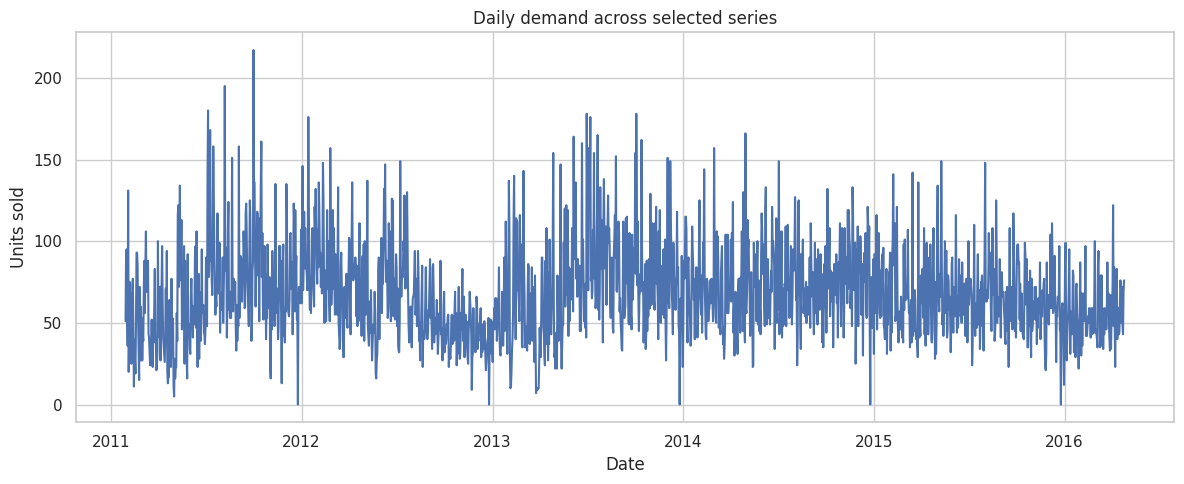

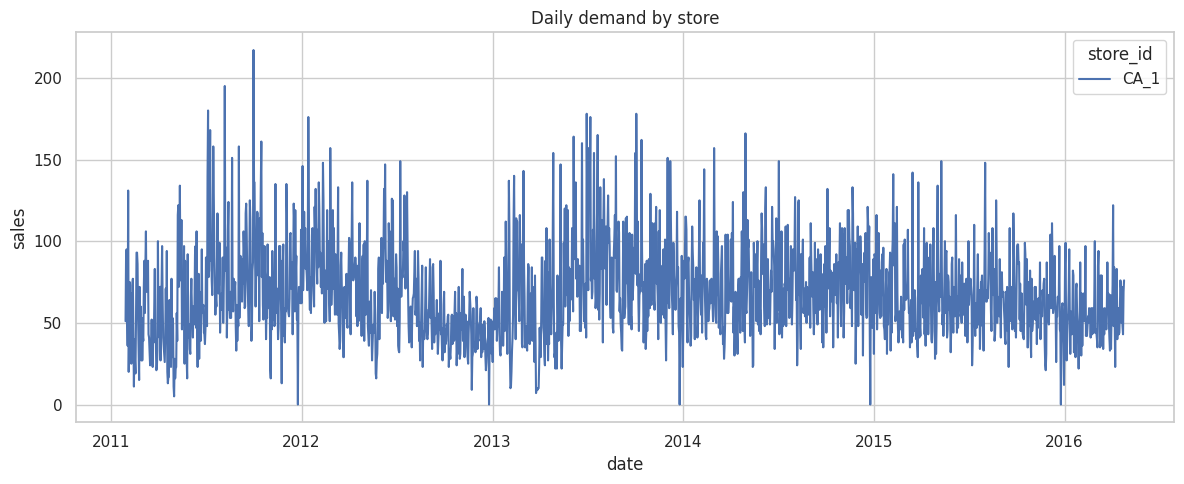

In [12]:
valid_daily = daily.dropna(subset=["sales"]).copy()
print("Recorded units in selected validation history:", valid_daily.sales.sum())
print("Mean units per observed item-day:", valid_daily.sales.mean())
print("Zero-sales share (%):", (valid_daily.sales.eq(0).mean() * 100).round(2))
print("Missing sales share (%):", daily.sales.isna().mean() * 100)

daily_total = valid_daily.groupby(["d_num", "date"], as_index=False).sales.sum()
plt.figure()
plt.plot(daily_total.date, daily_total.sales)
plt.title("Daily demand across selected series")
plt.xlabel("Date"); plt.ylabel("Units sold"); plt.tight_layout(); plt.show()

store_daily = valid_daily.groupby(["store_id", "date"], as_index=False).sales.sum()
plt.figure()
sns.lineplot(data=store_daily, x="date", y="sales", hue="store_id")
plt.title("Daily demand by store"); plt.tight_layout(); plt.show()

## 9. EDA — category, department and product demand
Compare demand contributions and identify high-volume products. The notebook only plots categories and departments present in the uploaded data.

,total_units,mean_item_day
cat_id,,
FOODS,"57,711.000",15.084
HOBBIES,"45,339.000",11.850
HOUSEHOLD,"27,297.000",7.135


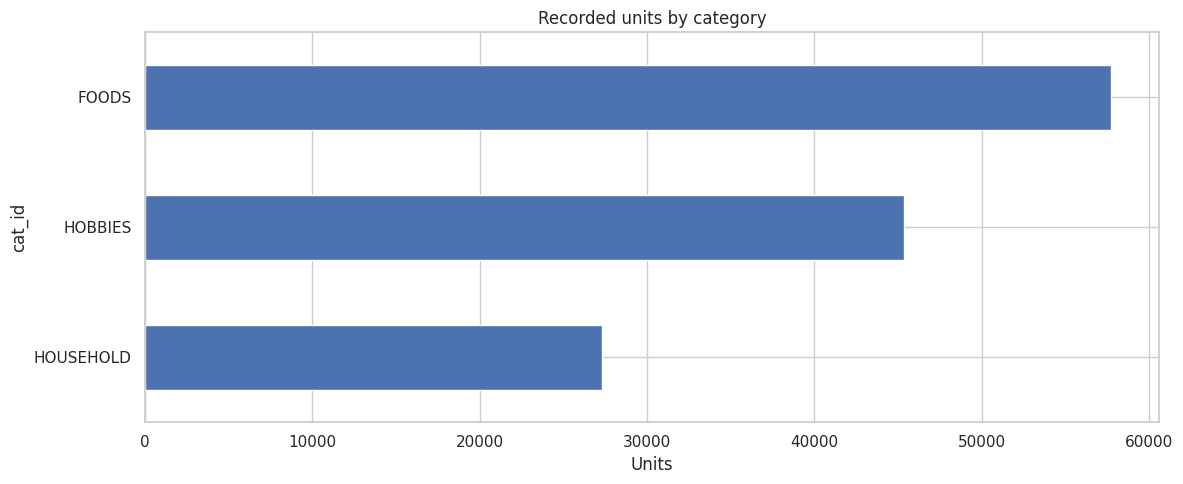

total_units
store_id dept_id                 
CA_1     HOBBIES_1     45,339.000
         FOODS_2       35,324.000
         HOUSEHOLD_1   27,297.000
         FOODS_1       22,387.000

,store_id,cat_id,item_id,total_units,average_daily_units,std_daily_units,zero_share
1,CA_1,FOODS,FOODS_2_019,"35,324.000",18.465,10.985,0.085
2,CA_1,HOBBIES,HOBBIES_1_348,"22,744.000",11.889,13.999,0.208
3,CA_1,HOBBIES,HOBBIES_1_371,"22,595.000",11.811,12.338,0.194
0,CA_1,FOODS,FOODS_1_218,"22,387.000",11.703,9.325,0.054
4,CA_1,HOUSEHOLD,HOUSEHOLD_1_118,"14,604.000",7.634,5.821,0.072
5,CA_1,HOUSEHOLD,HOUSEHOLD_1_535,"12,693.000",6.635,5.232,0.150


In [13]:
cat_summary = valid_daily.groupby("cat_id").sales.agg(total_units="sum", mean_item_day="mean").sort_values("total_units", ascending=False)
display(cat_summary)
plt.figure()
cat_summary.total_units.sort_values().plot(kind="barh")
plt.title("Recorded units by category"); plt.xlabel("Units"); plt.tight_layout(); plt.show()

dept_summary = valid_daily.groupby(["store_id", "dept_id"]).sales.sum().sort_values(ascending=False)
display(dept_summary.to_frame("total_units").head(20))

product_summary = valid_daily.groupby(["store_id", "cat_id", "item_id"]).sales.agg(
    total_units="sum", average_daily_units="mean", std_daily_units="std",
    zero_share=lambda s: (s == 0).mean()).reset_index()
display(product_summary.sort_values("total_units", ascending=False).head(15))

## 10. EDA — seasonality, events and intermittent demand
Inspect weekday, month, event-day and zero-sales patterns. These are descriptive associations and do not prove causation.

,mean_units_per_item_day
weekday,
Monday,10.750
Tuesday,10.284
Wednesday,9.845
Thursday,9.321
Friday,11.499
Saturday,13.718
Sunday,14.059


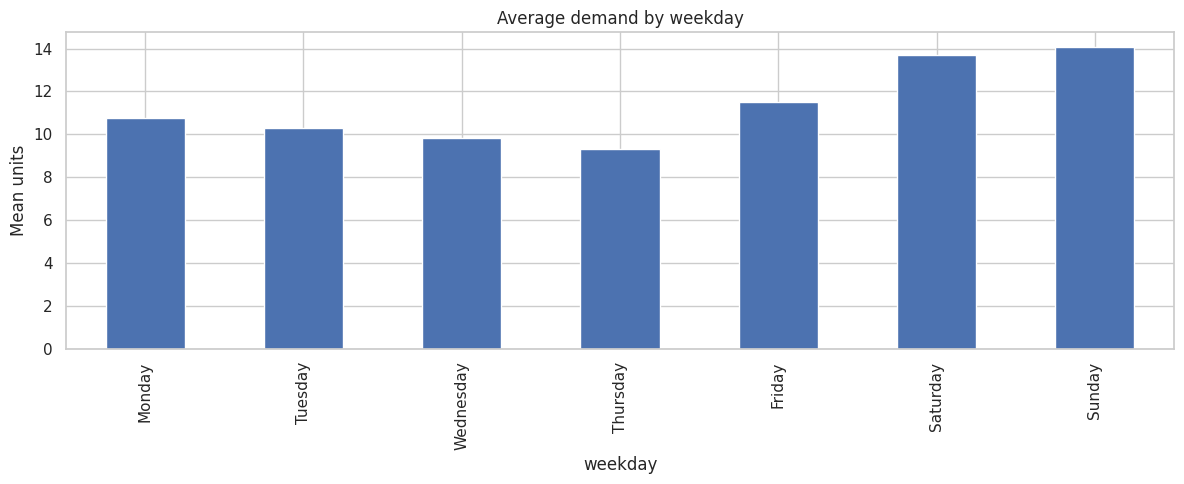

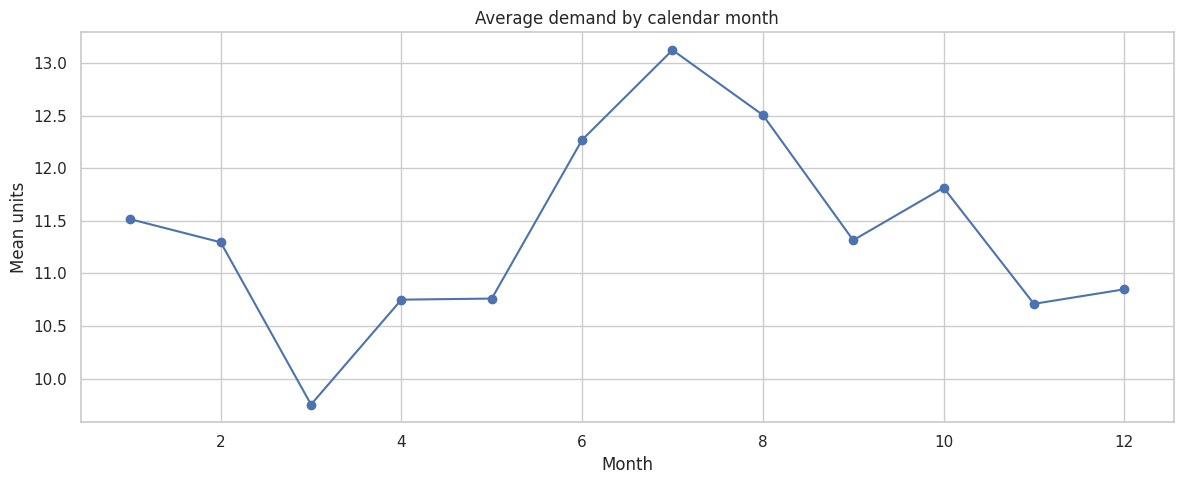

,mean,median,count
is_event,,,
False,11.458,9.000,10554
True,10.189,8.000,924


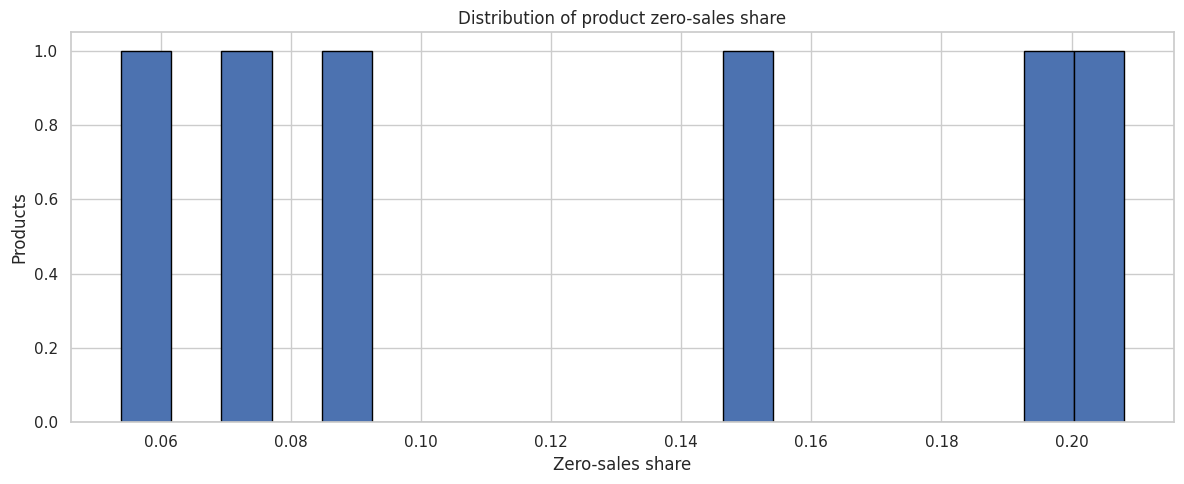

In [14]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_summary = valid_daily.groupby("weekday").sales.mean().reindex(weekday_order)
display(weekday_summary.to_frame("mean_units_per_item_day"))
plt.figure()
weekday_summary.plot(kind="bar")
plt.title("Average demand by weekday"); plt.ylabel("Mean units"); plt.tight_layout(); plt.show()

month_summary = valid_daily.groupby("month").sales.mean()
plt.figure()
month_summary.plot(marker="o")
plt.title("Average demand by calendar month"); plt.xlabel("Month"); plt.ylabel("Mean units"); plt.tight_layout(); plt.show()

valid_daily["is_event"] = valid_daily[["event_name_1", "event_name_2"]].notna().any(axis=1)
event_summary = valid_daily.groupby("is_event").sales.agg(["mean", "median", "count"])
display(event_summary)

zero_summary = valid_daily.groupby(["store_id", "cat_id", "item_id"]).sales.agg(
    zero_share=lambda s: (s == 0).mean(), mean_demand="mean").reset_index()
plt.figure()
plt.hist(zero_summary.zero_share, bins=20, edgecolor="black")
plt.title("Distribution of product zero-sales share"); plt.xlabel("Zero-sales share"); plt.ylabel("Products"); plt.tight_layout(); plt.show()

## 11. EDA — selling prices and SNAP indicators
Explore available price variation and SNAP calendar indicators. Price-demand associations are observational; SNAP flags are calendar indicators, not proof of individual customer eligibility or causal impact.

,sell_price
count,846.000
mean,0.641
std,0.234
min,0.420
25%,0.460
50%,0.500
75%,0.970
max,0.970


Correlation between price and units (descriptive): -0.18187206319259136


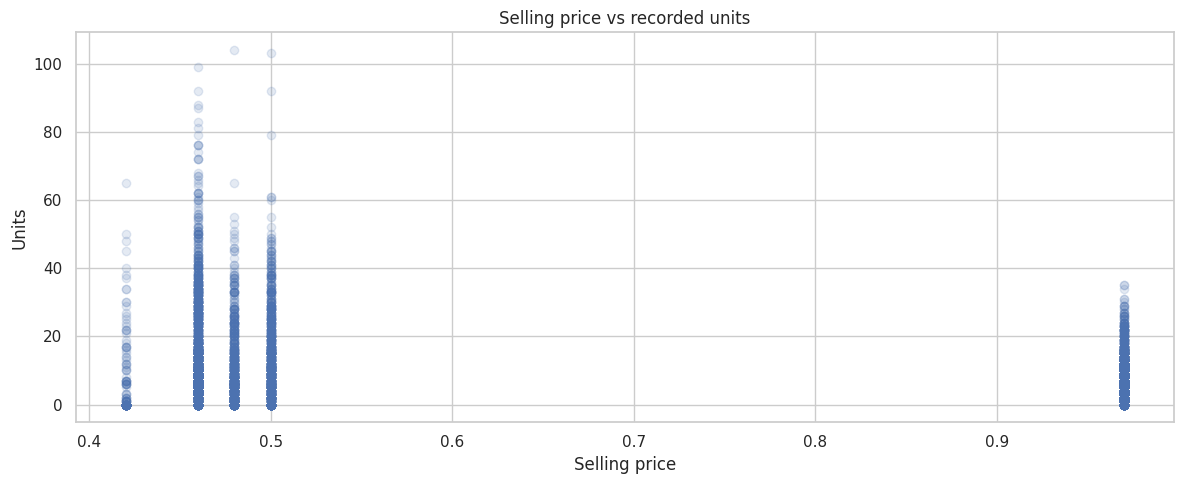

,mean,median,count
store_snap,,,
0,10.901,8.000,7698
1,12.283,9.000,3780


In [15]:
price_stats = prices[prices.store_id.isin(scope_model.store_id.unique()) &
                     prices.item_id.isin(scope_model.item_id.unique())].sell_price.describe()
display(price_stats.to_frame("sell_price"))
priced = daily.dropna(subset=["sales", "sell_price"])
if len(priced) > 1:
    print("Correlation between price and units (descriptive):", priced[["sales", "sell_price"]].corr().iloc[0,1])
    plt.figure()
    plt.scatter(priced.sell_price, priced.sales, alpha=0.15)
    plt.title("Selling price vs recorded units"); plt.xlabel("Selling price"); plt.ylabel("Units"); plt.tight_layout(); plt.show()

snap_cols = [c for c in ["snap_CA", "snap_TX", "snap_WI"] if c in valid_daily.columns]
if snap_cols:
    snap_col = {"CA_1":"snap_CA","CA_2":"snap_CA","TX_1":"snap_TX","TX_2":"snap_TX","WI_1":"snap_WI","WI_2":"snap_WI"}
    valid_daily["store_snap"] = valid_daily.apply(
        lambda r: r.get(snap_col.get(r.store_id), np.nan), axis=1)
    display(valid_daily.groupby("store_snap").sales.agg(["mean","median","count"]))

## 12. Define rolling-origin backtests
Use four consecutive, non-overlapping 28-day test windows at the end of the validation history. Each origin trains only on days before its test window. All model comparisons use identical series and dates.

In [16]:
all_val_nums = np.array([int(d.split("_")[1]) for d in val_days])
origins = []
for j in range(N_BACKTEST_ORIGINS, 0, -1):
    test_days = all_val_nums[-j*HORIZON:-(j-1)*HORIZON if j > 1 else None]
    if len(test_days) != HORIZON:
        continue
    origins.append({"origin": len(origins)+1, "train_end": int(test_days[0])-1,
                    "test_start": int(test_days[0]), "test_end": int(test_days[-1]),
                    "test_days": test_days.tolist()})
origin_table = pd.DataFrame([{k:v for k,v in o.items() if k!="test_days"} for o in origins])
display(origin_table)
assert len(origins) == N_BACKTEST_ORIGINS
assert all(o["train_end"] >= MIN_TRAIN_DAYS for o in origins)

,origin,train_end,test_start,test_end
0,1,1801,1802,1829
1,2,1829,1830,1857
2,3,1857,1858,1885
3,4,1885,1886,1913


## 13. Feature engineering — past-only demand and known covariates
Build lag and rolling features from observations strictly before each target day. Calendar and price features are included only when their values are available in the supplied files for that forecast day.

In [17]:
# Use integer codes for categorical identifiers. The same mapping is reused for all origins and final forecast.
item_codes = {v:i for i,v in enumerate(sorted(scope_model.item_id.unique()))}
store_codes = {v:i for i,v in enumerate(sorted(scope_model.store_id.unique()))}
cat_codes = {v:i for i,v in enumerate(sorted(scope_model.cat_id.unique()))}
dept_codes = {v:i for i,v in enumerate(sorted(scope_model.dept_id.unique()))}

series_meta = scope_model.set_index("id")[["item_id","store_id","cat_id","dept_id"]].to_dict("index")
history_by_id = {}
for sid, grp in val_long.groupby("id"):
    history_by_id[sid] = dict(zip(grp.d_num.astype(int), grp.sales.astype(float)))

# Weekly price lookup; no interpolation or forward filling of absent prices.
price_lookup = price_small.set_index(["store_id","item_id","wm_yr_wk"])["sell_price"].to_dict()

def covariates_for(sid, day_num):
    meta = series_meta[sid]
    cal = calendar_lookup.get(int(day_num), {})
    wk = cal.get("wm_yr_wk")
    price = price_lookup.get((meta["store_id"], meta["item_id"], wk), np.nan)
    prior_cal = calendar_lookup.get(max(1, int(day_num) - 7), {})
    prior_wk = prior_cal.get("wm_yr_wk")
    prior_price = price_lookup.get((meta["store_id"], meta["item_id"], prior_wk), np.nan)
    price_change = ((price / prior_price) - 1.0) if pd.notna(price) and pd.notna(prior_price) and prior_price != 0 else np.nan
    return {
        "item_code": item_codes[meta["item_id"]],
        "store_code": store_codes[meta["store_id"]],
        "category_code": cat_codes[meta["cat_id"]],
        "department_code": dept_codes[meta["dept_id"]],
        "wday": float(cal.get("wday", np.nan)),
        "month": float(cal.get("month", np.nan)),
        "year": float(cal.get("year", np.nan)),
        "is_weekend": int(cal.get("wday") in [1, 2]) if pd.notna(cal.get("wday", np.nan)) else 0,
        "is_event": int(pd.notna(cal.get("event_name_1")) or pd.notna(cal.get("event_name_2"))),
        "snap_CA": float(cal.get("snap_CA", 0) or 0),
        "snap_TX": float(cal.get("snap_TX", 0) or 0),
        "snap_WI": float(cal.get("snap_WI", 0) or 0),
        "sell_price": float(price) if pd.notna(price) else np.nan,
        "price_lag_7d": float(prior_price) if pd.notna(prior_price) else np.nan,
        "price_pct_change_7d": float(price_change) if pd.notna(price_change) else np.nan,
    }

def make_feature_row(sid, day_num, hist):
    vals = [hist.get(d, np.nan) for d in range(day_num-1, day_num-31, -1)]
    if any(pd.isna(v) for v in vals[:28]):
        return None
    a = np.asarray(vals, dtype=float)
    row = {
        "lag_1": a[0], "lag_3": a[2], "lag_7": a[6], "lag_14": a[13],
        "lag_28": a[27], "lag_30": a[29],
        "rolling_mean_7": a[:7].mean(), "rolling_mean_14": a[:14].mean(),
        "rolling_mean_28": a[:28].mean(), "rolling_std_14": a[:14].std(ddof=1),
        "rolling_max_7": a[:7].max(), "rolling_min_7": a[:7].min(),
    }
    row.update(covariates_for(sid, day_num))
    return row

FEATURE_COLS = ["item_code","store_code","category_code","department_code",
                "wday","month","year","is_weekend","is_event","snap_CA","snap_TX","snap_WI",
                 "sell_price","price_lag_7d","price_pct_change_7d","lag_1","lag_3","lag_7","lag_14","lag_28","lag_30",
                "rolling_mean_7","rolling_mean_14","rolling_mean_28","rolling_std_14",
                "rolling_max_7","rolling_min_7"]
print("Feature count:", len(FEATURE_COLS))

Feature count: 27


## 14. Build model training examples for each origin
Create one-step training rows from the origin's training history. Each feature row uses past demand only. Training rows with missing required features or missing target sales are excluded and counted.

In [18]:
def build_training_frame(train_end, histories=None):
    rows, targets = [], []
    histories = history_by_id if histories is None else histories
    for sid, hist in histories.items():
        for day_num in range(31, train_end + 1):
            target = hist.get(day_num, np.nan)
            if pd.isna(target):
                continue
            row = make_feature_row(sid, day_num, hist)
            if row is None:
                continue
            rows.append(row); targets.append(float(target))
    X = pd.DataFrame(rows, columns=FEATURE_COLS)
    y = pd.Series(targets, name="sales")
    if len(X):
        # A price can be unavailable in the source; retain the row and use median-price imputation learned from training only.
        X = X.replace([np.inf, -np.inf], np.nan)
    return X, y

X_first, y_first = build_training_frame(origins[0]["train_end"])
print("Earliest-origin training examples:", len(X_first))
print("Missing price feature share:", X_first.sell_price.isna().mean() if len(X_first) else np.nan)

Earliest-origin training examples: 10626
Missing price feature share: 0.5


## 15. Define models and evaluation metrics
Compare simple benchmarks, a statistical model and machine-learning models. XGBoost is optional; the notebook records whether it is available. WAPE is used instead of MAPE because zero actual demand makes MAPE unstable.

In [19]:
def metric_row(y_true, y_pred, model, origin):
    yt = np.asarray(y_true, dtype=float); yp = np.asarray(y_pred, dtype=float)
    err = yp - yt
    denom = np.abs(yt).sum()
    return {"origin": origin, "model": model,
            "MAE": mean_absolute_error(yt, yp),
            "RMSE": mean_squared_error(yt, yp) ** 0.5,
            "WAPE_pct": (np.abs(err).sum()/denom*100) if denom else np.nan,
            "bias_units": err.mean(),
            "bias_pct": (err.sum()/denom*100) if denom else np.nan}

def fit_ml_model(model_name, X, y):
    X = X.copy()
    medians = X.median(numeric_only=True)
    X = X.fillna(medians).fillna(0)
    if model_name == "Random Forest":
        model = RandomForestRegressor(n_estimators=80, max_depth=14, min_samples_leaf=5,
                                      max_features=0.75, n_jobs=-1,
                                      random_state=RANDOM_STATE)
    elif model_name in ["XGBoost", "Tuned XGBoost"]:
        if importlib.util.find_spec("xgboost") is None:
            return None, medians
        from xgboost import XGBRegressor
        if model_name == "Tuned XGBoost" and best_xgb_params is not None:
            model = XGBRegressor(**best_xgb_params,
                                 objective="reg:squarederror", n_jobs=-1,
                                 random_state=RANDOM_STATE)
        else:
            model = XGBRegressor(n_estimators=350, max_depth=7, learning_rate=0.04,
                                 subsample=0.85, colsample_bytree=0.85,
                                 objective="reg:squarederror", n_jobs=-1,
                                 random_state=RANDOM_STATE)
    model.fit(X, y)
    return model, medians

def predict_recursive_ml(model, medians, model_name, train_histories, test_days):
    preds = []
    working = {sid: dict(h) for sid,h in train_histories.items()}
    for day_num in test_days:
        for sid in working:
            row = make_feature_row(sid, day_num, working[sid])
            if row is None:
                pred = np.nan
            else:
                Xrow = pd.DataFrame([row], columns=FEATURE_COLS).fillna(medians).fillna(0)
                pred = max(0.0, float(model.predict(Xrow)[0]))
            working[sid][int(day_num)] = pred
            preds.append({"id":sid,"d_num":int(day_num),"prediction":pred})
    return pd.DataFrame(preds)

def benchmark_forecast(train_histories, test_days, method):
    out=[]
    for sid, hist in train_histories.items():
        observed = np.array([hist[d] for d in sorted(hist) if d <= test_days[0]-1 and pd.notna(hist[d])], dtype=float)
        if len(observed) < 28: continue
        working = dict(hist)
        for d in test_days:
            if method == "Naive":
                pred = observed[-1]
            elif method == "Seasonal Naive":
                pred = working.get(int(d)-7, observed[-1])
            elif method == "Moving Average":
                pred = np.mean(observed[-7:])
            else:
                continue
            pred = max(0.0, float(pred))
            working[int(d)] = pred
            out.append({"id":sid,"d_num":int(d),"prediction":pred})
    return pd.DataFrame(out)

best_xgb_params = None  # Set by the rolling-origin tuning cell if a tuned model wins.\nprint("XGBoost installed:", importlib.util.find_spec("xgboost") is not None)

## 16. Statistical Exponential Smoothing baseline
Fit an additive-trend, weekly-seasonal Exponential Smoothing model separately for each product series. If a series cannot be fitted, it is skipped and reported; no synthetic fallback result is inserted.

In [20]:
def ets_forecast(train_histories, test_days):
    try:
        from statsmodels.tsa.holtwinters import ExponentialSmoothing
    except ImportError:
        print("statsmodels unavailable; install it to run Exponential Smoothing.")
        return pd.DataFrame()
    rows=[]; failed=0
    for sid, hist in train_histories.items():
        end = test_days[0]-1
        arr = np.array([hist.get(d, np.nan) for d in range(1, end+1)], dtype=float)
        if np.isnan(arr).any() or len(arr) < 56:
            failed += 1; continue
        try:
            fit = ExponentialSmoothing(arr, trend="add", seasonal="add",
                                       seasonal_periods=7,
                                       initialization_method="estimated").fit(optimized=True)
            forecast = np.maximum(0, fit.forecast(len(test_days)))
            rows.extend({"id":sid,"d_num":int(d),"prediction":float(p)}
                        for d,p in zip(test_days, forecast))
        except Exception:
            failed += 1
    print("ETS series not fitted:", failed)
    return pd.DataFrame(rows)

## 17. Run the rolling-origin experiment
For every origin, train Random Forest and optional XGBoost using only pre-origin history. Forecast the complete 28-day horizon recursively. Compare against naive, seasonal-naive, moving-average and ETS baselines.

In [28]:
backtest_predictions = []
for origin in origins:
    oid, train_end, test_days = origin["origin"], origin["train_end"], origin["test_days"]
    print(f"Origin {oid}: train through d_{train_end}; test d_{test_days[0]}–d_{test_days[-1]}")
    train_hist = {sid:{d:v for d,v in h.items() if d <= train_end} for sid,h in history_by_id.items()}
    actual_rows = []
    for sid,h in history_by_id.items():
        for d in test_days:
            actual_rows.append({"origin":oid,"id":sid,"d_num":int(d),"actual":h.get(int(d),np.nan)})
    actual_df = pd.DataFrame(actual_rows)

    for method in ["Naive","Seasonal Naive","Moving Average"]:
        pred = benchmark_forecast(train_hist, test_days, method)
        pred["origin"] = oid; pred["model"] = method
        backtest_predictions.append(pred)

    ets = ets_forecast(train_hist, test_days)
    if not ets.empty:
        ets["origin"] = oid; ets["model"] = "Exponential Smoothing"
        backtest_predictions.append(ets)

    X_train, y_train = build_training_frame(train_end)
    for method in ["Random Forest"] + (["XGBoost"] if importlib.util.find_spec("xgboost") else []):
        model, medians = fit_ml_model(method, X_train, y_train)
        if model is None: continue
        pred = predict_recursive_ml(model, medians, method, train_hist, test_days)
        pred["origin"] = oid; pred["model"] = method
        backtest_predictions.append(pred)

bt_pred = pd.concat(backtest_predictions, ignore_index=True)
bt_actual = pd.concat([
    pd.DataFrame([{"origin":o["origin"],"id":sid,"d_num":int(d),
                   "actual":history_by_id[sid].get(int(d),np.nan)}
                  for sid in history_by_id for d in o["test_days"]])
    for o in origins
], ignore_index=True)
bt = bt_pred.merge(
    bt_actual,
    on=["origin", "id", "d_num"],
    how="inner",
    validate="many_to_one"
)
bt = bt.dropna(subset=["actual","prediction"])
print("Backtest prediction rows:", len(bt))

Origin 1: train through d_1801; test d_1802–d_1829
ETS series not fitted: 0
Origin 2: train through d_1829; test d_1830–d_1857
ETS series not fitted: 0
Origin 3: train through d_1857; test d_1858–d_1885
ETS series not fitted: 0
Origin 4: train through d_1885; test d_1886–d_1913
ETS series not fitted: 0
Backtest prediction rows: 4032


## 18. Aggregate model metrics and stability
Calculate metrics for each origin and overall pooled predictions. Compare both mean performance and variation across origins instead of selecting a model from one holdout alone.

,origin,model,MAE,RMSE,WAPE_pct,bias_units,bias_pct
0,ALL,Exponential Smoothing,4.925,6.778,53.154,-0.167,-1.800
1,ALL,Moving Average,5.194,7.052,56.060,0.003,0.032
3,ALL,Random Forest,5.724,7.481,61.777,2.388,25.775
5,ALL,XGBoost,5.772,7.614,62.296,2.301,24.840
4,ALL,Seasonal Naive,6.256,8.974,67.523,0.003,0.032
2,ALL,Naive,8.768,12.889,94.635,4.318,46.611


,mean_WAPE_pct,std_WAPE_pct,mean_MAE,mean_RMSE,mean_bias,origins_evaluated
model,,,,,,
Exponential Smoothing,53.175,2.839,4.925,6.761,-0.167,4
Moving Average,56.003,4.500,5.194,7.025,0.003,4
Random Forest,61.812,1.900,5.724,7.470,2.388,4
XGBoost,62.429,5.010,5.772,7.612,2.301,4
Seasonal Naive,67.442,3.648,6.256,8.956,0.003,4
Naive,95.718,30.506,8.768,12.408,4.318,4


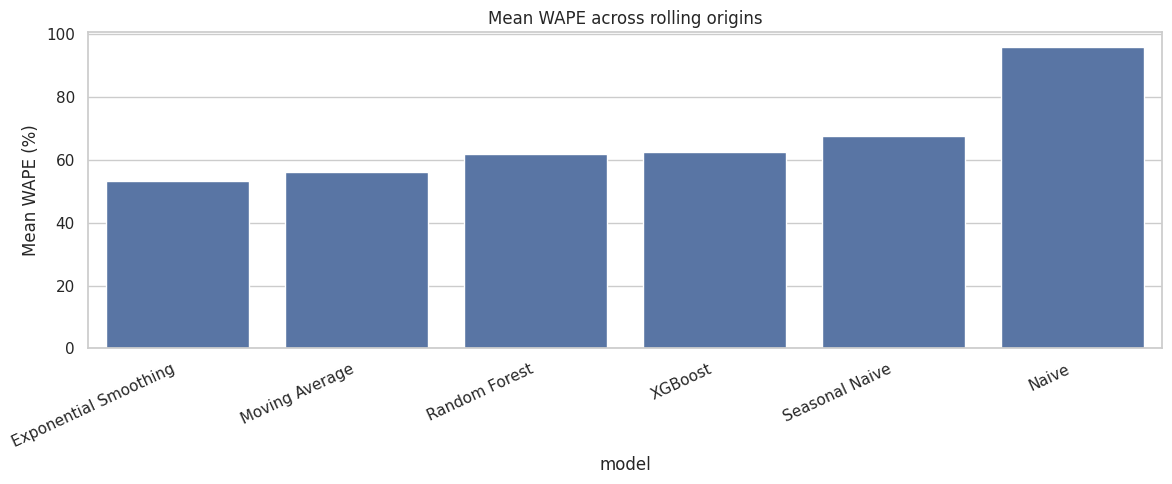

In [29]:
origin_metrics = pd.DataFrame([
    metric_row(g.actual, g.prediction, model, origin)
    for (origin, model), g in bt.groupby(["origin","model"])
])
overall_metrics = pd.DataFrame([
    metric_row(g.actual, g.prediction, model, "ALL")
    for model,g in bt.groupby("model")
]).sort_values("WAPE_pct")
stability = origin_metrics.groupby("model").agg(
    mean_WAPE_pct=("WAPE_pct","mean"),
    std_WAPE_pct=("WAPE_pct","std"),
    mean_MAE=("MAE","mean"),
    mean_RMSE=("RMSE","mean"),
    mean_bias=("bias_units","mean"),
    origins_evaluated=("origin","nunique")
).sort_values("mean_WAPE_pct")
display(overall_metrics)
display(stability)
plt.figure()
sns.barplot(data=stability.reset_index(), x="model", y="mean_WAPE_pct")
plt.title("Mean WAPE across rolling origins"); plt.ylabel("Mean WAPE (%)")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

## 19. Time-aware XGBoost tuning

Tune a small, deliberately bounded set of XGBoost configurations using the same four rolling-origin windows. Each candidate is trained only on data available before that origin and is evaluated on its subsequent 28 days. The best candidate is compared with the original XGBoost baseline using mean WAPE across all origins.

This is a practical validation-based model-selection step, not a claim that the tuned model must win. If none of the candidates beats the baseline, the original XGBoost model remains selected. The selected parameters are then reused when fitting on the evaluation history.

**Runtime note:** this adds up to 12 XGBoost fits (3 candidates × 4 origins), so it may take several minutes in Colab.


In [30]:

# ============================================================
# CELL 43: TIME-AWARE XGBOOST HYPERPARAMETER TUNING
# ============================================================

from xgboost import XGBRegressor
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Define candidate hyperparameter configurations
# ------------------------------------------------------------

xgb_candidates = {
    "xgb_depth4_lr003": {
        "n_estimators": 450,
        "max_depth": 4,
        "learning_rate": 0.03,
        "subsample": 0.90,
        "colsample_bytree": 0.90,
        "min_child_weight": 5,
        "reg_lambda": 5.0
    },

    "xgb_depth5_lr003": {
        "n_estimators": 450,
        "max_depth": 5,
        "learning_rate": 0.03,
        "subsample": 0.90,
        "colsample_bytree": 0.90,
        "min_child_weight": 5,
        "reg_lambda": 5.0
    },

    "xgb_depth6_lr005": {
        "n_estimators": 450,
        "max_depth": 6,
        "learning_rate": 0.05,
        "subsample": 0.90,
        "colsample_bytree": 0.90,
        "min_child_weight": 5,
        "reg_lambda": 5.0
    }
}

# ------------------------------------------------------------
# 2. Initialize result containers
# ------------------------------------------------------------

candidate_origin_rows = []

candidate_predictions = {
    name: [] for name in xgb_candidates
}

# ------------------------------------------------------------
# 3. Run tuning across all rolling origins
# ------------------------------------------------------------

for candidate_name, params in xgb_candidates.items():

    print(f"\nEvaluating: {candidate_name}")

    for origin in origins:

        oid = origin["origin"]
        train_end = origin["train_end"]
        test_days = origin["test_days"]

        # Build training data using only history before this origin
        X_train, y_train = build_training_frame(train_end)

        if len(X_train) == 0:
            print(f"Skipping origin {oid}: no training data")
            continue

        # Handle missing feature values using training medians
        X_train = X_train.copy()
        medians = X_train.median(numeric_only=True)

        X_train = X_train.fillna(medians).fillna(0)

        # Train candidate model
        model = XGBRegressor(
            **params,
            objective="reg:squarederror",
            n_jobs=-1,
            random_state=RANDOM_STATE
        )

        model.fit(X_train, y_train)

        # Create training histories for this origin
        train_hist = {
            sid: {
                d: value
                for d, value in hist.items()
                if d <= train_end
            }
            for sid, hist in history_by_id.items()
        }

        # Generate recursive 28-day predictions
        pred = predict_recursive_ml(
            model,
            medians,
            candidate_name,
            train_hist,
            test_days
        )

        # Add origin and model information
        pred["origin"] = oid
        pred["model"] = candidate_name

        # Get actual values for the forecast horizon
        actual_rows = []

        for sid in history_by_id:
            for d in test_days:
                actual_rows.append({
                    "id": sid,
                    "d_num": int(d),
                    "actual": history_by_id[sid].get(
                        int(d), np.nan
                    )
                })

        actual_df = pd.DataFrame(actual_rows)

        # Merge actual and predicted values
        scored = pred.merge(
            actual_df,
            on=["id", "d_num"],
            how="inner",
            validate="one_to_one"
        )

        # Remove missing values
        scored = scored.dropna(
            subset=["actual", "prediction"]
        )

        if scored.empty:
            print(f"Skipping origin {oid}: no valid predictions")
            continue

        # Calculate metrics
        row = metric_row(
            scored["actual"],
            scored["prediction"],
            candidate_name,
            oid
        )

        candidate_origin_rows.append(row)

        # Store actual and prediction together
        candidate_predictions[candidate_name].append(
            scored[
                [
                    "id",
                    "d_num",
                    "actual",
                    "prediction",
                    "origin",
                    "model"
                ]
            ].copy()
        )

        print(
            f"Origin {oid}: "
            f"WAPE = {row['WAPE_pct']:.3f}%"
        )


# ------------------------------------------------------------
# 4. Aggregate tuning results
# ------------------------------------------------------------

tuning_results = pd.DataFrame(candidate_origin_rows)

if tuning_results.empty:
    raise ValueError(
        "No valid tuning results were generated. "
        "Check the rolling origins and training data."
    )

tuning_summary = (
    tuning_results
    .groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        std_WAPE_pct=("WAPE_pct", "std"),
        mean_MAE=("MAE", "mean"),
        mean_RMSE=("RMSE", "mean")
    )
    .sort_values("mean_WAPE_pct")
)

print("\nTUNING RESULTS")
display(tuning_summary)


# ------------------------------------------------------------
# 5. Identify the best candidate
# ------------------------------------------------------------

best_candidate = tuning_summary.index[0]

best_candidate_wape = tuning_summary.loc[
    best_candidate, "mean_WAPE_pct"
]

print("\nBest candidate:", best_candidate)

print(
    f"Best candidate mean WAPE: "
    f"{best_candidate_wape:.3f}%"
)


# ------------------------------------------------------------
# 6. Compare with original XGBoost baseline
# ------------------------------------------------------------

baseline_xgb = bt[
    bt["model"] == "XGBoost"
].copy()

if baseline_xgb.empty:
    raise ValueError(
        "Original XGBoost results are missing from bt. "
        "Run Cell 39 before running this cell."
    )

baseline_origin_metrics = []

for oid, group in baseline_xgb.groupby("origin"):

    baseline_origin_metrics.append(
        metric_row(
            group["actual"],
            group["prediction"],
            "XGBoost",
            oid
        )
    )

baseline_wape = np.mean([
    row["WAPE_pct"]
    for row in baseline_origin_metrics
])

print(
    f"\nOriginal XGBoost mean WAPE: "
    f"{baseline_wape:.3f}%"
)


# ------------------------------------------------------------
# 7. Select tuned model only if it improves baseline
# ------------------------------------------------------------

if best_candidate_wape < baseline_wape:

    print("\nTuned XGBoost improves the baseline.")

    # Save selected parameters for final model refitting
    best_xgb_params = xgb_candidates[best_candidate].copy()

    # Collect selected candidate predictions
    tuned_bt = pd.concat(
        candidate_predictions[best_candidate],
        ignore_index=True
    )

    # Ensure there are no missing values
    tuned_bt = tuned_bt.dropna(
        subset=["actual", "prediction"]
    )

    # Add tuned predictions to the backtest dataframe
    bt = pd.concat(
        [bt, tuned_bt],
        ignore_index=True
    )

    selected_xgb_model = best_candidate

else:

    print(
        "\nTuning did not improve the baseline. "
        "Keeping original XGBoost."
    )

    best_xgb_params = None
    selected_xgb_model = "XGBoost"


# ------------------------------------------------------------
# 8. Refresh backtest metrics
# ------------------------------------------------------------

bt = bt.dropna(
    subset=["actual", "prediction"]
).copy()

origin_metrics = pd.DataFrame([
    metric_row(
        group["actual"],
        group["prediction"],
        model_name,
        origin_id
    )
    for (origin_id, model_name), group
    in bt.groupby(["origin", "model"])
])

overall_metrics = pd.DataFrame([
    metric_row(
        group["actual"],
        group["prediction"],
        model_name,
        "ALL"
    )
    for model_name, group in bt.groupby("model")
]).sort_values("WAPE_pct")


# ------------------------------------------------------------
# 9. Updated model stability comparison
# ------------------------------------------------------------

stability = (
    origin_metrics
    .groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        std_WAPE_pct=("WAPE_pct", "std"),
        mean_MAE=("MAE", "mean"),
        mean_RMSE=("RMSE", "mean"),
        mean_bias=("bias_units", "mean"),
        origins_evaluated=("origin", "nunique")
    )
    .sort_values("mean_WAPE_pct")
)

print("\nUPDATED OVERALL MODEL METRICS")
display(overall_metrics)

print("\nUPDATED MODEL STABILITY")
display(stability)

print("\nSelected XGBoost model:", selected_xgb_model)

print("\nSelected XGBoost parameters:")
print(best_xgb_params)



Evaluating: xgb_depth4_lr003
Origin 1: WAPE = 56.695%
Origin 2: WAPE = 58.909%
Origin 3: WAPE = 59.043%
Origin 4: WAPE = 55.808%

Evaluating: xgb_depth5_lr003
Origin 1: WAPE = 58.046%
Origin 2: WAPE = 60.414%
Origin 3: WAPE = 61.091%
Origin 4: WAPE = 54.709%

Evaluating: xgb_depth6_lr005
Origin 1: WAPE = 63.042%
Origin 2: WAPE = 55.883%
Origin 3: WAPE = 64.070%
Origin 4: WAPE = 56.009%

TUNING RESULTS


,mean_WAPE_pct,std_WAPE_pct,mean_MAE,mean_RMSE
model,,,,
xgb_depth4_lr003,57.614,1.615,5.335,7.028
xgb_depth5_lr003,58.565,2.883,5.419,7.145
xgb_depth6_lr005,59.751,4.414,5.524,7.305



Best candidate: xgb_depth4_lr003
Best candidate mean WAPE: 57.614%

Original XGBoost mean WAPE: 62.429%

Tuned XGBoost improves the baseline.

UPDATED OVERALL MODEL METRICS


,origin,model,MAE,RMSE,WAPE_pct,bias_units,bias_pct
0,ALL,Exponential Smoothing,4.925,6.778,53.154,-0.167,-1.800
1,ALL,Moving Average,5.194,7.052,56.060,0.003,0.032
6,ALL,xgb_depth4_lr003,5.335,7.035,57.586,1.460,15.762
3,ALL,Random Forest,5.724,7.481,61.777,2.388,25.775
5,ALL,XGBoost,5.772,7.614,62.296,2.301,24.840
4,ALL,Seasonal Naive,6.256,8.974,67.523,0.003,0.032
2,ALL,Naive,8.768,12.889,94.635,4.318,46.611



UPDATED MODEL STABILITY


,mean_WAPE_pct,std_WAPE_pct,mean_MAE,mean_RMSE,mean_bias,origins_evaluated
model,,,,,,
Exponential Smoothing,53.175,2.839,4.925,6.761,-0.167,4
Moving Average,56.003,4.500,5.194,7.025,0.003,4
xgb_depth4_lr003,57.614,1.615,5.335,7.028,1.460,4
Random Forest,61.812,1.900,5.724,7.470,2.388,4
XGBoost,62.429,5.010,5.772,7.612,2.301,4
Seasonal Naive,67.442,3.648,6.256,8.956,0.003,4
Naive,95.718,30.506,8.768,12.408,4.318,4



Selected XGBoost model: xgb_depth4_lr003

Selected XGBoost parameters:
{'n_estimators': 450, 'max_depth': 4, 'learning_rate': 0.03, 'subsample': 0.9, 'colsample_bytree': 0.9, 'min_child_weight': 5, 'reg_lambda': 5.0}


## 20. Category, store and product-level error analysis
Inspect whether overall model rankings hide weak performance in particular stores, categories or products. Use the best mean-WAPE model across origins as the diagnostic reference.

In [31]:
best_model = stability.index[0]
best_bt = bt[bt.model == best_model].copy()
best_bt["abs_error"] = (best_bt.prediction - best_bt.actual).abs()
best_bt = best_bt.merge(scope_model[["id","store_id","cat_id","dept_id","item_id"]], on="id", how="left")
category_error = best_bt.groupby("cat_id").apply(
    lambda g: pd.Series({"MAE":g.abs_error.mean(),
                         "WAPE_pct":g.abs_error.sum()/g.actual.abs().sum()*100}),
    include_groups=False).sort_values("WAPE_pct")
product_error = best_bt.groupby(["store_id","cat_id","item_id"]).apply(
    lambda g: pd.Series({"MAE":g.abs_error.mean(),
                         "WAPE_pct":g.abs_error.sum()/g.actual.abs().sum()*100,
                         "actual_units":g.actual.sum()}),
    include_groups=False).reset_index().sort_values("WAPE_pct", ascending=False)
display(category_error)
display(product_error.head(15))

,MAE,WAPE_pct
cat_id,,
FOODS,4.990,38.742
HOUSEHOLD,3.109,41.848
HOBBIES,6.676,89.166


,store_id,cat_id,item_id,MAE,WAPE_pct,actual_units
2,CA_1,HOBBIES,HOBBIES_1_348,6.068,99.797,681.000
3,CA_1,HOBBIES,HOBBIES_1_371,7.283,81.897,996.000
0,CA_1,FOODS,FOODS_1_218,5.190,55.150,"1,054.000"
4,CA_1,HOUSEHOLD,HOUSEHOLD_1_118,3.844,49.088,877.000
5,CA_1,HOUSEHOLD,HOUSEHOLD_1_535,2.374,33.781,787.000
1,CA_1,FOODS,FOODS_2_019,4.790,29.297,"1,831.000"


## 21. Forecast error diagnostics
Plot aggregate actual versus predicted demand and inspect residual distribution. Positive residuals mean overforecasting; negative residuals mean underforecasting.

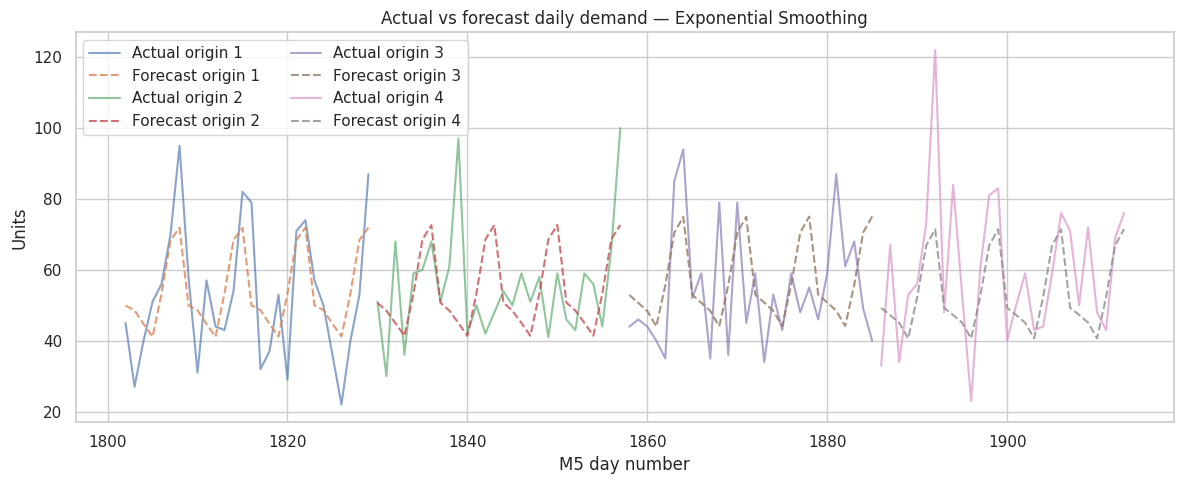

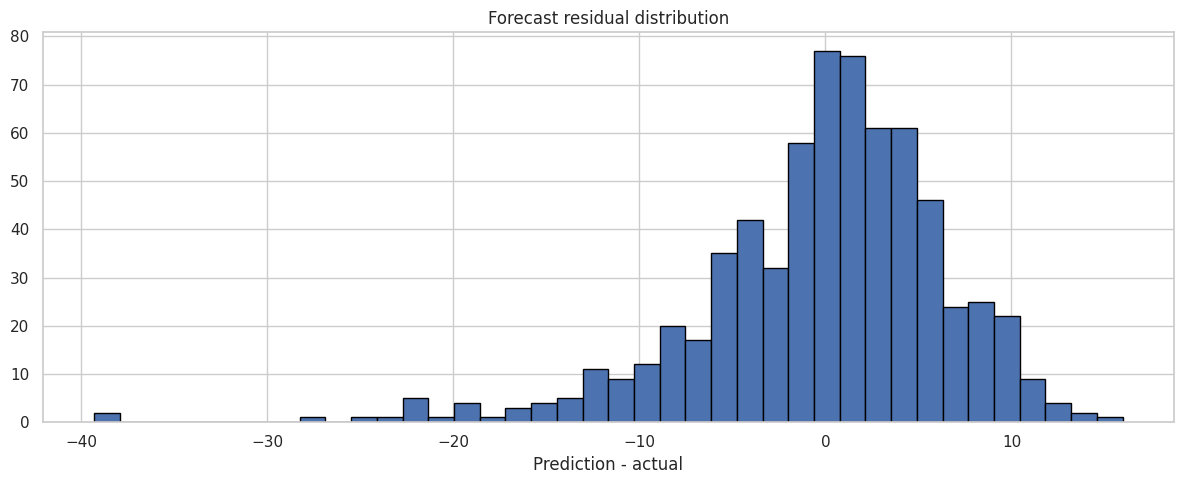

Selected model by mean rolling WAPE: Exponential Smoothing


In [32]:
best_daily = best_bt.groupby(["origin","d_num"]).agg(actual=("actual","sum"),
    prediction=("prediction","sum")).reset_index()
plt.figure()
for oid,g in best_daily.groupby("origin"):
    plt.plot(g.d_num, g.actual, alpha=0.65, label=f"Actual origin {oid}")
    plt.plot(g.d_num, g.prediction, linestyle="--", alpha=0.8, label=f"Forecast origin {oid}")
plt.title(f"Actual vs forecast daily demand — {best_model}")
plt.xlabel("M5 day number"); plt.ylabel("Units"); plt.legend(ncol=2); plt.tight_layout(); plt.show()

residuals = best_bt.prediction - best_bt.actual
plt.figure()
plt.hist(residuals, bins=40, edgecolor="black")
plt.title("Forecast residual distribution"); plt.xlabel("Prediction - actual"); plt.tight_layout(); plt.show()
print("Selected model by mean rolling WAPE:", best_model)

## 22. Refit the selected model on the evaluation history
The final evaluation snapshot contains the extended history used to produce the next 28-day forecast. Refit the selected model using all available complete evaluation histories for the selected item-store series.

In [33]:
# Match validation-selected item-store pairs to evaluation rows; IDs have different suffixes.
selected_pairs = scope_model[["item_id","store_id","cat_id","dept_id","state_id"]].drop_duplicates(["item_id","store_id"])
eval_scope = sales_eval.merge(selected_pairs[["item_id","store_id"]], on=["item_id","store_id"],
                              how="inner", validate="one_to_one")
eval_id_map = eval_scope[["id","item_id","store_id"]].merge(
    scope_model[["id","item_id","store_id"]], on=["item_id","store_id"],
    suffixes=("_eval","_val"), validate="one_to_one")
eval_scope = eval_scope.merge(eval_id_map[["id_eval","id_val"]], left_on="id", right_on="id_eval",
                              how="left", validate="one_to_one")
eval_scope["id"] = eval_scope["id_val"]
eval_scope = eval_scope.drop(columns=["id_eval","id_val"])
eval_long = wide_to_long(eval_scope, eval_days)
eval_missing = eval_long.groupby("id").sales.apply(lambda s: s.isna().any())
eval_complete_ids = eval_missing[~eval_missing].index.tolist()
eval_long = eval_long[eval_long.id.isin(eval_complete_ids)].copy()
print("Selected series with complete evaluation history:", len(eval_complete_ids), "of", len(selected_ids))
if len(eval_complete_ids) == 0:
    raise ValueError("No complete evaluation histories matched selected validation series.")

eval_history = {}
for sid,g in eval_long.groupby("id"):
    eval_history[sid] = dict(zip(g.d_num.astype(int), g.sales.astype(float)))
eval_end = max(int(d.split("_")[1]) for d in eval_days)
future_days = list(range(eval_end+1, eval_end+HORIZON+1))
print("Evaluation history ends at d_", eval_end, "; forecast days d_", future_days[0],
      "–d_", future_days[-1], sep="")

Selected series with complete evaluation history: 5 of 6
Evaluation history ends at d_1941; forecast days d_1942–d_1969


## 23. Produce the final 28-day forecast
Refit the selected method on the full evaluation history and forecast recursively where applicable. If the selected model is ETS, fit one model per series. The future calendar and price features are used only when present in the supplied files.

In [34]:
if best_model in ["Naive","Seasonal Naive","Moving Average"]:
    final_pred = benchmark_forecast(eval_history, future_days, best_model)
elif best_model == "Exponential Smoothing":
    final_pred = ets_forecast(eval_history, future_days)
else:
    X_final, y_final = build_training_frame(eval_end, eval_history)
    final_fit, final_medians = fit_ml_model(best_model, X_final, y_final)
    final_pred = predict_recursive_ml(final_fit, final_medians, best_model, eval_history, future_days)

final_pred = final_pred.merge(scope_model[["id","item_id","store_id","cat_id","dept_id"]],
                              on="id", how="left", validate="many_to_one")
future_calendar = calendar[calendar.d_num.isin(future_days)][["d_num","date","weekday","wm_yr_wk"]]
final_forecast = final_pred.merge(future_calendar, on="d_num", how="left", validate="many_to_one")
print("Forecast rows:", len(final_forecast))
print("Forecast days with calendar dates:", final_forecast.date.notna().sum(), "of", len(final_forecast))
display(final_forecast.head())

ETS series not fitted: 0
Forecast rows: 140
Forecast days with calendar dates: 140 of 140


,id,d_num,prediction,item_id,store_id,cat_id,dept_id,date,weekday,wm_yr_wk
0,FOODS_1_218_CA_1_validation,1942,1.423,FOODS_1_218,CA_1,FOODS,FOODS_1,2016-05-23,Monday,11617
1,FOODS_1_218_CA_1_validation,1943,1.633,FOODS_1_218,CA_1,FOODS,FOODS_1,2016-05-24,Tuesday,11617
2,FOODS_1_218_CA_1_validation,1944,1.547,FOODS_1_218,CA_1,FOODS,FOODS_1,2016-05-25,Wednesday,11617
3,FOODS_1_218_CA_1_validation,1945,1.723,FOODS_1_218,CA_1,FOODS,FOODS_1,2016-05-26,Thursday,11617
4,FOODS_1_218_CA_1_validation,1946,4.138,FOODS_1_218,CA_1,FOODS,FOODS_1,2016-05-27,Friday,11617


## 24. Forecast summaries and checks
Summarise forecasts by store, category and product. Check for negative predictions, missing future calendar dates and incomplete forecast coverage.

,store_id,cat_id,forecast_units,average_daily_forecast
0,CA_1,FOODS,97.202,3.471
1,CA_1,HOBBIES,520.898,9.302
2,CA_1,HOUSEHOLD,402.623,7.190


,store_id,cat_id,item_id,forecast_28d_units
2,CA_1,HOBBIES,HOBBIES_1_371,283.428
1,CA_1,HOBBIES,HOBBIES_1_348,237.471
3,CA_1,HOUSEHOLD,HOUSEHOLD_1_118,235.701
4,CA_1,HOUSEHOLD,HOUSEHOLD_1_535,166.921
0,CA_1,FOODS,FOODS_1_218,97.202


Negative forecast values: 0
Missing forecast values: 0
Forecasted total units: 1020.7228433727005


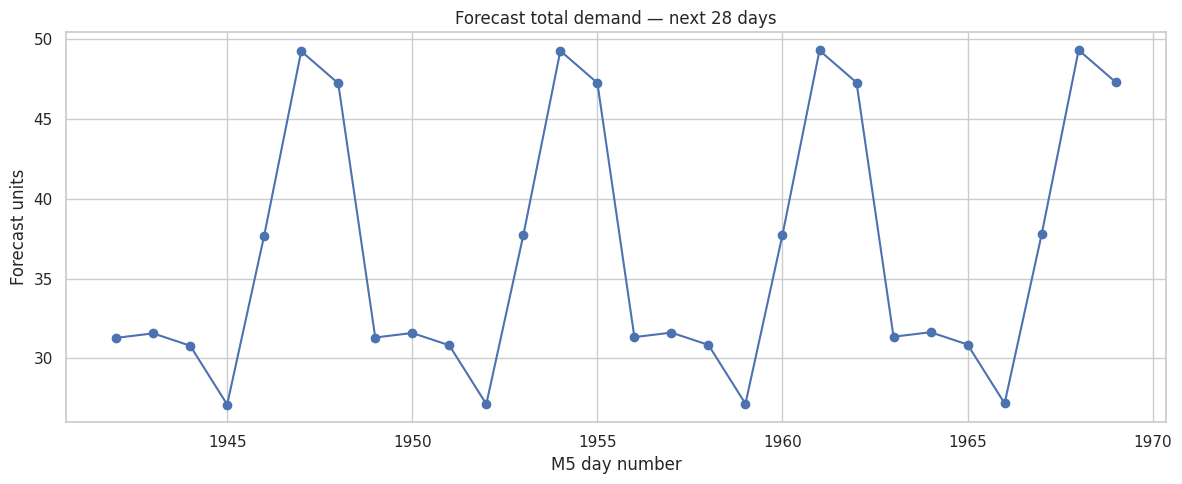

In [35]:
forecast_summary = final_forecast.groupby(["store_id","cat_id"]).prediction.agg(
    forecast_units="sum", average_daily_forecast="mean").reset_index()
product_forecast = final_forecast.groupby(["store_id","cat_id","item_id"]).prediction.sum().reset_index(name="forecast_28d_units")
display(forecast_summary)
display(product_forecast.sort_values("forecast_28d_units", ascending=False).head(20))
print("Negative forecast values:", int((final_forecast.prediction < 0).sum()))
print("Missing forecast values:", int(final_forecast.prediction.isna().sum()))
print("Forecasted total units:", final_forecast.prediction.sum())
daily_forecast_total = final_forecast.groupby("d_num").prediction.sum()
plt.figure()
daily_forecast_total.plot(marker="o")
plt.title("Forecast total demand — next 28 days"); plt.xlabel("M5 day number"); plt.ylabel("Forecast units")
plt.tight_layout(); plt.show()

## 25. Inventory planning using forecast uncertainty
Estimate product-level demand over the lead time, safety stock and reorder point. Safety stock uses the standard deviation of rolling-backtest one-step residuals and a normal quantile approximation. This is an assumption-based planning method, not a value supplied by M5.

In [36]:
from statistics import NormalDist
z_value = NormalDist().inv_cdf(SERVICE_LEVEL)
resid_df = best_bt[["id","prediction","actual"]].copy()
resid_df["residual"] = resid_df.prediction - resid_df.actual
resid_stats = resid_df.groupby("id").residual.agg(residual_std="std", residual_mean="mean").reset_index()
daily_future = final_forecast.copy()
inventory_rows = []
for sid,g in daily_future.groupby("id"):
    g = g.sort_values("d_num")
    lead_n = min(LEAD_TIME_DAYS, len(g))
    review_n = min(REVIEW_PERIOD_DAYS, len(g))
    lead_demand = float(g.prediction.head(lead_n).sum())
    review_demand = float(g.prediction.head(review_n).sum())
    rs = resid_stats[resid_stats.id == sid]
    sigma = float(rs.residual_std.iloc[0]) if len(rs) and pd.notna(rs.residual_std.iloc[0]) else 0.0
    safety_stock = max(0.0, z_value * sigma * np.sqrt(LEAD_TIME_DAYS))
    reorder_point = lead_demand + safety_stock
    target_stock = lead_demand + review_demand + safety_stock
    order_qty = max(0, int(np.ceil(target_stock - ON_HAND_UNITS)))
    meta = g.iloc[0]
    inventory_rows.append({
        "id":sid,"item_id":meta.item_id,"store_id":meta.store_id,"cat_id":meta.cat_id,
        "forecast_lead_time_demand":lead_demand,"daily_residual_std":sigma,
        "safety_stock":safety_stock,"reorder_point":reorder_point,
        "on_hand_scenario":ON_HAND_UNITS,"target_stock":target_stock,
        "suggested_order_qty":order_qty
    })
inventory_plan = pd.DataFrame(inventory_rows)
display(inventory_plan.sort_values("suggested_order_qty", ascending=False).head(20))

,id,item_id,store_id,cat_id,forecast_lead_time_demand,daily_residual_std,safety_stock,reorder_point,on_hand_scenario,target_stock,suggested_order_qty
2,HOBBIES_1_371_CA_1_validation,HOBBIES_1_371,CA_1,HOBBIES,71.083,9.322,40.566,111.649,0,182.732,183
1,HOBBIES_1_348_CA_1_validation,HOBBIES_1_348,CA_1,HOBBIES,59.230,8.120,35.335,94.566,0,153.796,154
3,HOUSEHOLD_1_118_CA_1_validation,HOUSEHOLD_1_118,CA_1,HOUSEHOLD,58.872,4.957,21.574,80.446,0,139.319,140
4,HOUSEHOLD_1_535_CA_1_validation,HOUSEHOLD_1_535,CA_1,HOUSEHOLD,41.458,3.123,13.592,55.050,0,96.509,97
0,FOODS_1_218_CA_1_validation,FOODS_1_218,CA_1,FOODS,24.286,6.913,30.085,54.371,0,78.656,79


## 26. Inventory sensitivity analysis
Compare reorder points under different lead times and service levels. The forecast daily demand profile is summed over each lead time; safety stock uses the same estimated daily residual variability.

In [37]:
scenario_rows = []
for _,r in inventory_plan.iterrows():
    for lead in [3,7,14]:
        for service in [0.90,0.95,0.99]:
            z = NormalDist().inv_cdf(service)
            lead_demand = float(final_forecast[final_forecast.id == r.id].sort_values("d_num").prediction.head(lead).sum())
            safety = max(0.0, z * r.daily_residual_std * np.sqrt(lead))
            scenario_rows.append({"id":r.id,"item_id":r.item_id,"store_id":r.store_id,
                                  "cat_id":r.cat_id,"lead_time_days":lead,
                                  "service_level":service,"lead_time_demand":lead_demand,
                                  "safety_stock":safety,"reorder_point":lead_demand+safety,
                                  "suggested_order_qty":max(0,int(np.ceil(lead_demand+safety-ON_HAND_UNITS)))})
inventory_sensitivity = pd.DataFrame(scenario_rows)
display(inventory_sensitivity.head(18))

,id,item_id,store_id,cat_id,lead_time_days,service_level,lead_time_demand,safety_stock,reorder_point,suggested_order_qty
0,FOODS_1_218_CA_1_validation,FOODS_1_218,CA_1,FOODS,3,0.900,4.603,15.345,19.948,20
1,FOODS_1_218_CA_1_validation,FOODS_1_218,CA_1,FOODS,3,0.950,4.603,19.695,24.298,25
2,FOODS_1_218_CA_1_validation,FOODS_1_218,CA_1,FOODS,3,0.990,4.603,27.855,32.458,33
3,FOODS_1_218_CA_1_validation,FOODS_1_218,CA_1,FOODS,7,0.900,24.286,23.440,47.726,48
4,FOODS_1_218_CA_1_validation,FOODS_1_218,CA_1,FOODS,7,0.950,24.286,30.085,54.371,55
5,FOODS_1_218_CA_1_validation,FOODS_1_218,CA_1,FOODS,7,0.990,24.286,42.550,66.836,67
6,FOODS_1_218_CA_1_validation,FOODS_1_218,CA_1,FOODS,14,0.900,48.581,33.149,81.730,82
7,FOODS_1_218_CA_1_validation,FOODS_1_218,CA_1,FOODS,14,0.950,48.581,42.547,91.128,92
8,FOODS_1_218_CA_1_validation,FOODS_1_218,CA_1,FOODS,14,0.990,48.581,60.175,108.756,109
9,HOBBIES_1_348_CA_1_validation,HOBBIES_1_348,CA_1,HOBBIES,3,0.900,23.039,18.023,41.062,42


## 27. Business findings generated from observed results
Generate findings from the computed metrics and forecasts. Interpret them as findings for the selected modelling scope, not as claims about every store or product in the full dataset.

In [38]:
print("PROJECT FINDINGS")
print("="*65)
print(f"Stores included: {', '.join(sorted(scope_model.store_id.unique()))}")
print(f"Selected series: {scope_model.id.nunique()} / {sales_val.id.nunique()} validation series")
print(f"Categories represented: {', '.join(sorted(scope_model.cat_id.unique()))}")
print(f"Best mean rolling-origin model: {best_model}")
print(f"Mean rolling-origin WAPE: {stability.loc[best_model,'mean_WAPE_pct']:.2f}%")
top_cat = forecast_summary.groupby("cat_id").forecast_units.sum().sort_values(ascending=False)
if len(top_cat):
    print(f"Largest forecast category in selected scope: {top_cat.index[0]} ({top_cat.iloc[0]:,.1f} units)")
top_item = product_forecast.sort_values("forecast_28d_units", ascending=False).head(1)
if len(top_item):
    print("Highest forecast item:", top_item.iloc[0].item_id,
          f"({top_item.iloc[0].forecast_28d_units:,.1f} units)")
print(f"Total 28-day forecast: {final_forecast.prediction.sum():,.1f} units")
print("Inventory quantities are scenario outputs based on stated lead time, service level and on-hand assumptions.")

PROJECT FINDINGS
Stores included: CA_1
Selected series: 6 / 1869 validation series
Categories represented: FOODS, HOBBIES, HOUSEHOLD
Best mean rolling-origin model: Exponential Smoothing
Mean rolling-origin WAPE: 53.18%
Largest forecast category in selected scope: HOBBIES (520.9 units)
Highest forecast item: HOBBIES_1_371 (283.4 units)
Total 28-day forecast: 1,020.7 units
Inventory quantities are scenario outputs based on stated lead time, service level and on-hand assumptions.


## 28. Export reproducible project outputs
Export model metrics, per-origin metrics, backtest predictions, final forecasts, inventory plans and sensitivity scenarios. The exports reflect the current configuration and selected modelling scope.

In [40]:

# ============================================================
# EXPORT PROJECT OUTPUTS
# ============================================================

# 1. Export overall model metrics
overall_metrics.to_csv(
    OUTPUT_DIR / "overall_model_metrics.csv",
    index=False
)

# 2. Export XGBoost tuning comparison, if available
if "tuning_comparison" in globals() and not tuning_comparison.empty:
    tuning_comparison.to_csv(
        OUTPUT_DIR / "xgboost_tuning_comparison.csv"
    )

# 3. Export rolling-origin metrics
origin_metrics.to_csv(
    OUTPUT_DIR / "rolling_origin_metrics.csv",
    index=False
)

# 4. Export model stability summary
stability.to_csv(
    OUTPUT_DIR / "model_stability_summary.csv"
)

# 5. Export backtest predictions
bt.to_csv(
    OUTPUT_DIR / "backtest_predictions.csv",
    index=False
)

# 6. Export final 28-day forecast
final_forecast.to_csv(
    OUTPUT_DIR / "final_28_day_forecast.csv",
    index=False
)

# 7. Export forecast summary
forecast_summary.to_csv(
    OUTPUT_DIR / "forecast_summary_by_store_category.csv",
    index=False
)

# 8. Export inventory scenario plan
inventory_plan.to_csv(
    OUTPUT_DIR / "inventory_scenario_plan.csv",
    index=False
)

# 9. Export inventory sensitivity analysis
inventory_sensitivity.to_csv(
    OUTPUT_DIR / "inventory_sensitivity.csv",
    index=False
)

# 10. Display exported files
print("Exported files:")

for f in sorted(OUTPUT_DIR.glob("*.csv")):
    print(f, f.stat().st_size, "bytes")


Exported files:
retail_forecasting_outputs/backtest_predictions.csv 326572 bytes
retail_forecasting_outputs/final_28_day_forecast.csv 16450 bytes
retail_forecasting_outputs/forecast_summary_by_store_category.csv 201 bytes
retail_forecasting_outputs/inventory_scenario_plan.csv 928 bytes
retail_forecasting_outputs/inventory_sensitivity.csv 5688 bytes
retail_forecasting_outputs/model_stability_summary.csv 840 bytes
retail_forecasting_outputs/overall_model_metrics.csv 826 bytes
retail_forecasting_outputs/rolling_origin_metrics.csv 3070 bytes
retail_forecasting_outputs/xgboost_tuning_comparison.csv 411 bytes


## 29. Optional full M5 submission-format forecast
The selected-scope forecast above is intended for analysis and inventory planning. A full competition-style submission requires all series in the evaluation snapshot and both validation/evaluation forecast horizons. This cell checks the sample submission structure and explains the additional work; it does not fabricate forecasts for unmodelled series.

In [41]:
print("Sample submission columns:", sample_submission.columns.tolist()[:8], "...", sample_submission.columns.tolist()[-3:])
print("Sample submission rows:", len(sample_submission))
print("Selected modelling series:", len(selected_ids))
print("A competition submission is not generated by this selected-scope notebook.")

Sample submission columns: ['id', 'F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7'] ... ['F26', 'F27', 'F28']
Sample submission rows: 60980
Selected modelling series: 6
A competition submission is not generated by this selected-scope notebook.


## 30. Limitations and interpretation
- The default modelling subset is selected for practical runtime; results do not represent all products unless `TOP_N_PER_CATEGORY=None`.
- Product selection is based on the earliest training window, not on holdout demand.
- Rolling-origin validation is stronger than a single split but four origins are still a limited sample of possible demand conditions.
- Missing sales are not assumed to be zero. Incomplete histories are excluded from this modelling experiment.
- Missing prices are not imputed from future values. The model uses a training-median fallback for missing price feature values.
- SNAP and event comparisons are descriptive, not causal.
- M5 does not supply on-hand inventory, supplier lead time, purchase pack sizes, ordering costs or a service-level target. Inventory outputs are illustrative scenarios.
- Forecast accuracy is measured on the selected series and tested windows; it is not a guarantee of future performance.

## 31. Final quality-control checklist
Run the notebook from top to bottom and confirm the checks below. Keep the saved outputs with the exact configuration used to produce them.

In [42]:
checks = {
    "Five source CSVs loaded": all(p.exists() for p in paths.values()),
    "No duplicate validation series IDs": sales_val.id.duplicated().sum() == 0,
    "No duplicate evaluation series IDs": sales_eval.id.duplicated().sum() == 0,
    "Calendar keys unique": calendar.d_num.duplicated().sum() == 0,
    "Price composite keys unique": prices.duplicated(["store_id","item_id","wm_yr_wk"]).sum() == 0,
    "Four rolling origins created": len(origins) == N_BACKTEST_ORIGINS,
    "Backtest metrics produced": not overall_metrics.empty,
    "Final forecast produced": not final_forecast.empty,
    "Forecasts non-negative": (final_forecast.prediction.dropna() >= 0).all(),
    "Inventory plan produced": not inventory_plan.empty,
}
for label, passed in checks.items():
    print(("PASS" if passed else "CHECK") + " — " + label)
if not all(checks.values()):
    print("Review any CHECK items before publishing the project.")
else:
    print("\nNotebook quality checks passed for this run.")

PASS — Five source CSVs loaded
PASS — No duplicate validation series IDs
PASS — No duplicate evaluation series IDs
PASS — Calendar keys unique
PASS — Price composite keys unique
PASS — Four rolling origins created
PASS — Backtest metrics produced
PASS — Final forecast produced
PASS — Forecasts non-negative
PASS — Inventory plan produced

Notebook quality checks passed for this run.


## 32. Suggested GitHub project structure
After validating the notebook outputs, organise the repository as follows. Do not commit the large raw M5 CSVs unless their licence and repository size policy allow it.

```text
retail-demand-forecasting/
├── notebooks/
│   └── Retail_Demand_Forecasting.ipynb
├── outputs/
│   ├── overall_model_metrics.csv
│   ├── rolling_origin_metrics.csv
│   ├── final_28_day_forecast.csv
│   └── inventory_scenario_plan.csv
├── README.md
├── requirements.txt
└── .gitignore
```

**Portfolio summary:** Built a retail demand forecasting and inventory planning workflow using the M5 dataset, with data validation, demand analysis, lag-based feature engineering, rolling-origin model comparison, 28-day recursive forecasts and assumption-based reorder planning.